# Tugas 2 : CountVectorizer dan TF-IDF pada teks ulasan

In [1]:
# Langkah 1 - Load dan preprocessing
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv('../../dataset_pbl/reviews.csv')
df = df[['rating', 'text']].rename(columns={'rating': 'Labels', 'text': 'Teks'})
df['Labels'] = df['Labels'].map({1: 0, 2: 1, 3: 2, 4: 3, 5: 4})
df.head()

,Labels,Teks
0,4,"Rekomendasi buat tempat ngopi, pisang goreng n..."
1,4,"Teh susux enak, ngupi sambil melihat lalu lalang"
2,4,tempat santai dan ena buat nongkrong rame rame
3,4,Resmi menamatkan Warkop Djayantie
4,4,Pisang goreng nya JUARA !\nharus coba pokoknya


In [2]:
# Langkah 2 - Split 80:20
from sklearn.model_selection import train_test_split
X = df['Teks'].to_numpy(dtype=str)
y = df['Labels'].to_numpy(dtype=int)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=50, stratify=y)

In [3]:
# Langkah 3 - CountVectorizer dengan stop words seperti contoh tugas
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
bow = CountVectorizer(stop_words='english')
train_bow = bow.fit_transform(X_train)
test_bow = bow.transform(X_test)
mnb_bow = MultinomialNB().fit(train_bow, y_train)
y_pred_bow = mnb_bow.predict(test_bow)

In [4]:
# Langkah 4 - TF-IDF dengan stop words seperti contoh tugas
tfidf = TfidfVectorizer(stop_words='english')
train_tfidf = tfidf.fit_transform(X_train)
test_tfidf = tfidf.transform(X_test)
mnb_tfidf = MultinomialNB().fit(train_tfidf, y_train)
y_pred_tfidf = mnb_tfidf.predict(test_tfidf)

In [5]:
# Langkah 5 - Evaluasi dan perbandingan
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report
hasil = []
for nama, pred in [('CountVectorizer', y_pred_bow), ('TF-IDF', y_pred_tfidf)]:
    print(nama)
    print(classification_report(y_test, pred, zero_division=0))
    hasil.append({'Fitur': nama, 'Akurasi': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred, average='weighted', zero_division=0),
        'Recall': recall_score(y_test, pred, average='weighted', zero_division=0),
        'F1': f1_score(y_test, pred, average='weighted', zero_division=0)})
tabel_hasil = pd.DataFrame(hasil)
tabel_hasil

CountVectorizer
              precision    recall  f1-score   support

           0       0.73      0.64      0.68       115
           1       1.00      0.05      0.10        37
           2       0.50      0.04      0.08        48
           3       0.43      0.11      0.17       138
           4       0.85      0.98      0.91      1264

    accuracy                           0.84      1602
   macro avg       0.70      0.37      0.39      1602
weighted avg       0.80      0.84      0.79      1602

TF-IDF
              precision    recall  f1-score   support

           0       1.00      0.03      0.07       115
           1       0.00      0.00      0.00        37
           2       0.00      0.00      0.00        48
           3       0.00      0.00      0.00       138
           4       0.79      1.00      0.88      1264

    accuracy                           0.79      1602
   macro avg       0.36      0.21      0.19      1602
weighted avg       0.70      0.79      0.70      1602


,Fitur,Akurasi,Precision,Recall,F1
0,CountVectorizer,0.835206,0.800360,0.835206,0.790071
1,TF-IDF,0.791511,0.695886,0.791511,0.701760


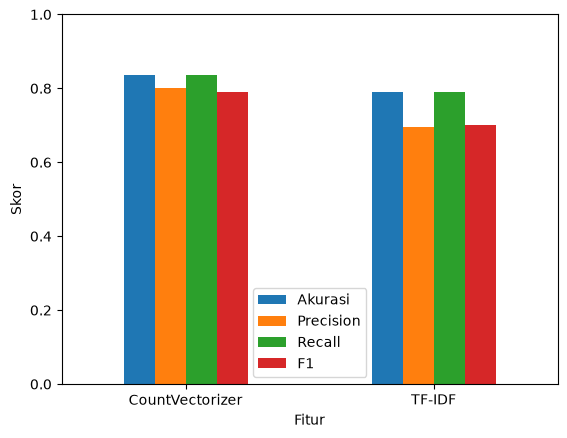

In [6]:
# Langkah 6 - Visualisasi perbandingan
tabel_hasil.set_index('Fitur').plot.bar(rot=0)
plt.ylabel('Skor')
plt.ylim(0, 1)
plt.show()

## Hasil

Akurasi CountVectorizer : 83.52% dan TF-IDF : 79.15%. targetnya adalah rating ulasan, bukan label spam atau sentimen